# **Drilling Analysis**
## Drilling by operator

This notebook contains code to generate a chart showing **monthly drilling by operator.**

**First,** import drilling data

In [1]:
# Import libraries
import pandas as pd
import os
import matplotlib.pyplot as plt
from matplotlib import lines

In [2]:
# Load data
PATH = os.path.join('..', '..', 'data', 'oil_intermediate')
df_op = pd.read_csv(PATH + '/02_drill_op.csv')

In [6]:
df_op

,fecha,cuenca,ubicacion,categoria,pozos_perforados
0,2002-01-01,Burgos,Terrestre,Desarrollo,33
1,2002-01-01,Burgos,Terrestre,Exploración,2
2,2002-01-01,Veracruz,Terrestre,Exploración,1
3,2002-02-01,Burgos,Terrestre,Desarrollo,31
4,2002-02-01,Burgos,Terrestre,Exploración,3
...,...,...,...,...,...
1406,2018-12-01,Sureste,Terrestre,Exploración,1
1407,2018-12-01,Aguas Profundas,Maritima,Exploración,1
1408,2018-12-01,Tampico-Misantla,Terrestre,Desarrollo,6
1409,2018-12-01,Tampico-Misantla,Terrestre,Exploración,1


**Second,** aggregate by location

In [3]:
# Group by and aggregate for land and offshore
df_agg = (
    df_op.query('ubicacion == "Terrestre"')
    .groupby(['ubicacion', 'fecha'], as_index=False)
    .agg(n_wells_land = ('pozos_perforados', 'sum'))[['fecha', 'n_wells_land']]
    .merge(
        df_op.query('ubicacion == "Maritima"')
        .groupby(['ubicacion', 'fecha'], as_index=False)
        .agg(n_wells_offshore = ('pozos_perforados', 'sum'))[['fecha', 'n_wells_offshore']],
        how='left',
        on='fecha'
    )
    .fillna(0)
)

**Third,** create a chart for the two aggregated series

In [4]:
# Year labels for x-axis labels
x_labels = []


for i in range(2002, 2020, 2):

    l = f'{i}'
    x_labels.append(l)

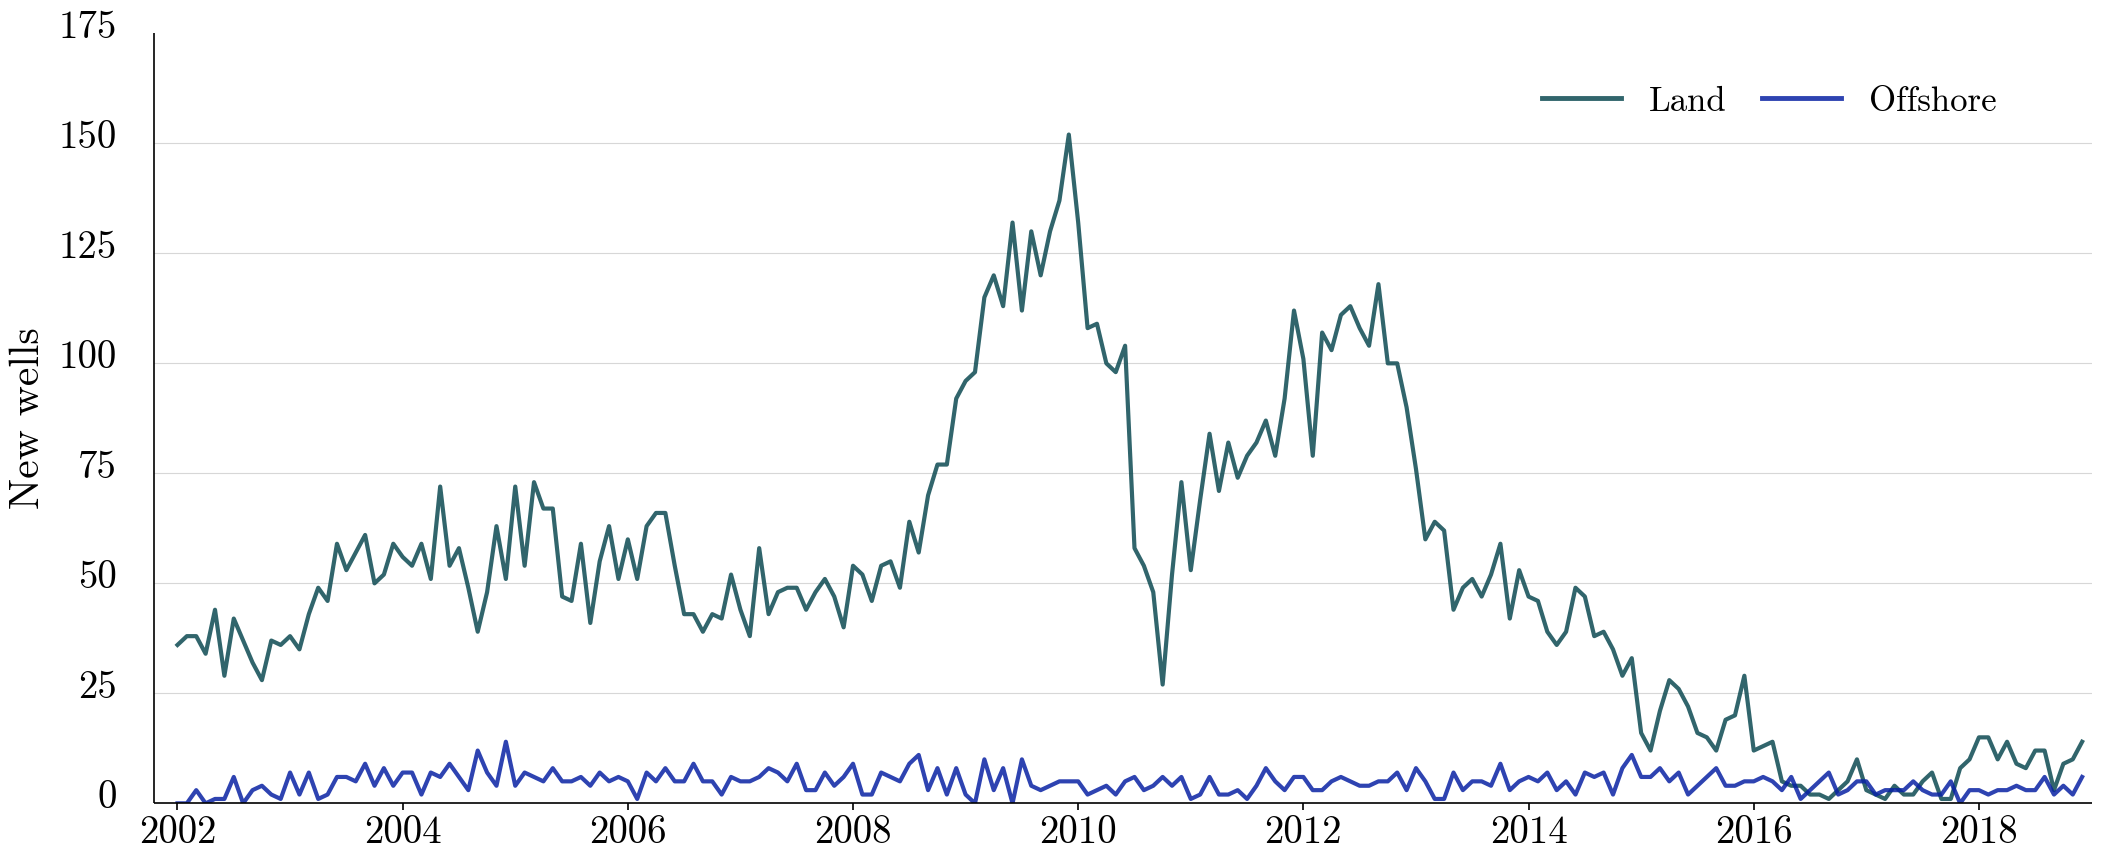

In [58]:
# Create subplots object
fig, ax = plt.subplots(figsize=(25,10))

# Y-axis settings
ax.set_ylim(0, 175)
ax.set_ylabel('New wells', fontsize=30, fontweight=100, fontfamily="cmr10") # <- Axis name label
ax.yaxis.set_label_coords(-0.055, 0.5)
ax.yaxis.set_tick_params(labelleft=False, length=0)
ax.yaxis.set_ticks(list(range(0, 151, 25)))

# Y-axis labels
for i in range(0,176,25):

    ax.text(
        -6.5, i-1, f'{i:,}', 
        ha="right", va="baseline", fontsize=28,
        fontfamily="cmr10", fontweight=100
    )

# X-axis settings
ax.set_xlim(-2.5, 204)
ax.xaxis.set_ticks(list(range(0, 216, 24)))
ax.xaxis.set_ticklabels(x_labels, fontsize=28, fontweight=100, fontfamily="cmr10")
ax.xaxis.set_tick_params(length=5, width=1.2)

# Spine settings
ax.spines["bottom"].set_lw(1.2)
ax.spines["bottom"].set_capstyle("butt")
ax.spines['left'].set_lw(1.2)
ax.spines['left'].set_capstyle("butt")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Grid settings
ax.grid(axis='y', alpha=0.5)

# Series
ax.plot(df_agg['n_wells_land'].values, lw=3, color="#0D4A52", alpha=0.85)
ax.plot(df_agg['n_wells_offshore'].values, lw=3, color="#0922A4", alpha=0.85)

# Legend settings
legend_handles = [
    lines.Line2D([0], [0], color="#0D4A52", lw=3.5, alpha=0.85, label="Land"),
    lines.Line2D([0], [0], color="#0922A4", lw=3.5, alpha=0.85, label="Offshore")
]

ax.legend(
    handles=legend_handles,
    loc="lower left",
    bbox_to_anchor=(0.7, 0.85),
    bbox_transform=ax.transAxes,
    frameon=False,
    ncol=2,
    handlelength=2.3,
    columnspacing=1.0,
    prop={"family": "cmr10", "size": 25}
)

# Tight layout
#fig.tight_layout()

# Show plot
plt.show()



Now, let's plot the two available drilling series to see how much they differ

In [6]:
# Import the well inventory
df_inventory = pd.read_csv(PATH+'/02_well_inventory.csv')
df_inventory['production_start'] = pd.to_datetime(df_inventory['production_start'], format='%Y-%m-%d')

# Aggregate wells by month (2000-2018)
df_drill = (
    df_inventory[(df_inventory['production_start'].dt.year>1999) & (df_inventory['production_start'].dt.year<2019)]
    .groupby(['production_start'], as_index=False)
    .agg(
        n_wells_pr = ('nombre_pozo', 'count')
    )
)

In [7]:
# Estimate total monthly drilling in the drilling by operator series
df_agg['n_wells_op'] = df_agg['n_wells_land'] + df_agg['n_wells_offshore']

Merge the two series in one single dataframe

In [8]:
# Set 'fecha as datetime' toe merge properly
df_agg['fecha'] = pd.to_datetime(df_agg['fecha'], format='%Y-%m-%d')

df_drill = (
    df_drill.rename(columns={'production_start':'fecha'})
    .merge(
        df_agg[['fecha', 'n_wells_op']],
        how='left',
        on='fecha'
    )
)

Plot the two series

In [9]:
# Year labels for x-axis labels
x_labels_02 = []

for i in range(2000, 2020, 2):

    l = f'{i}'
    x_labels_02.append(l)

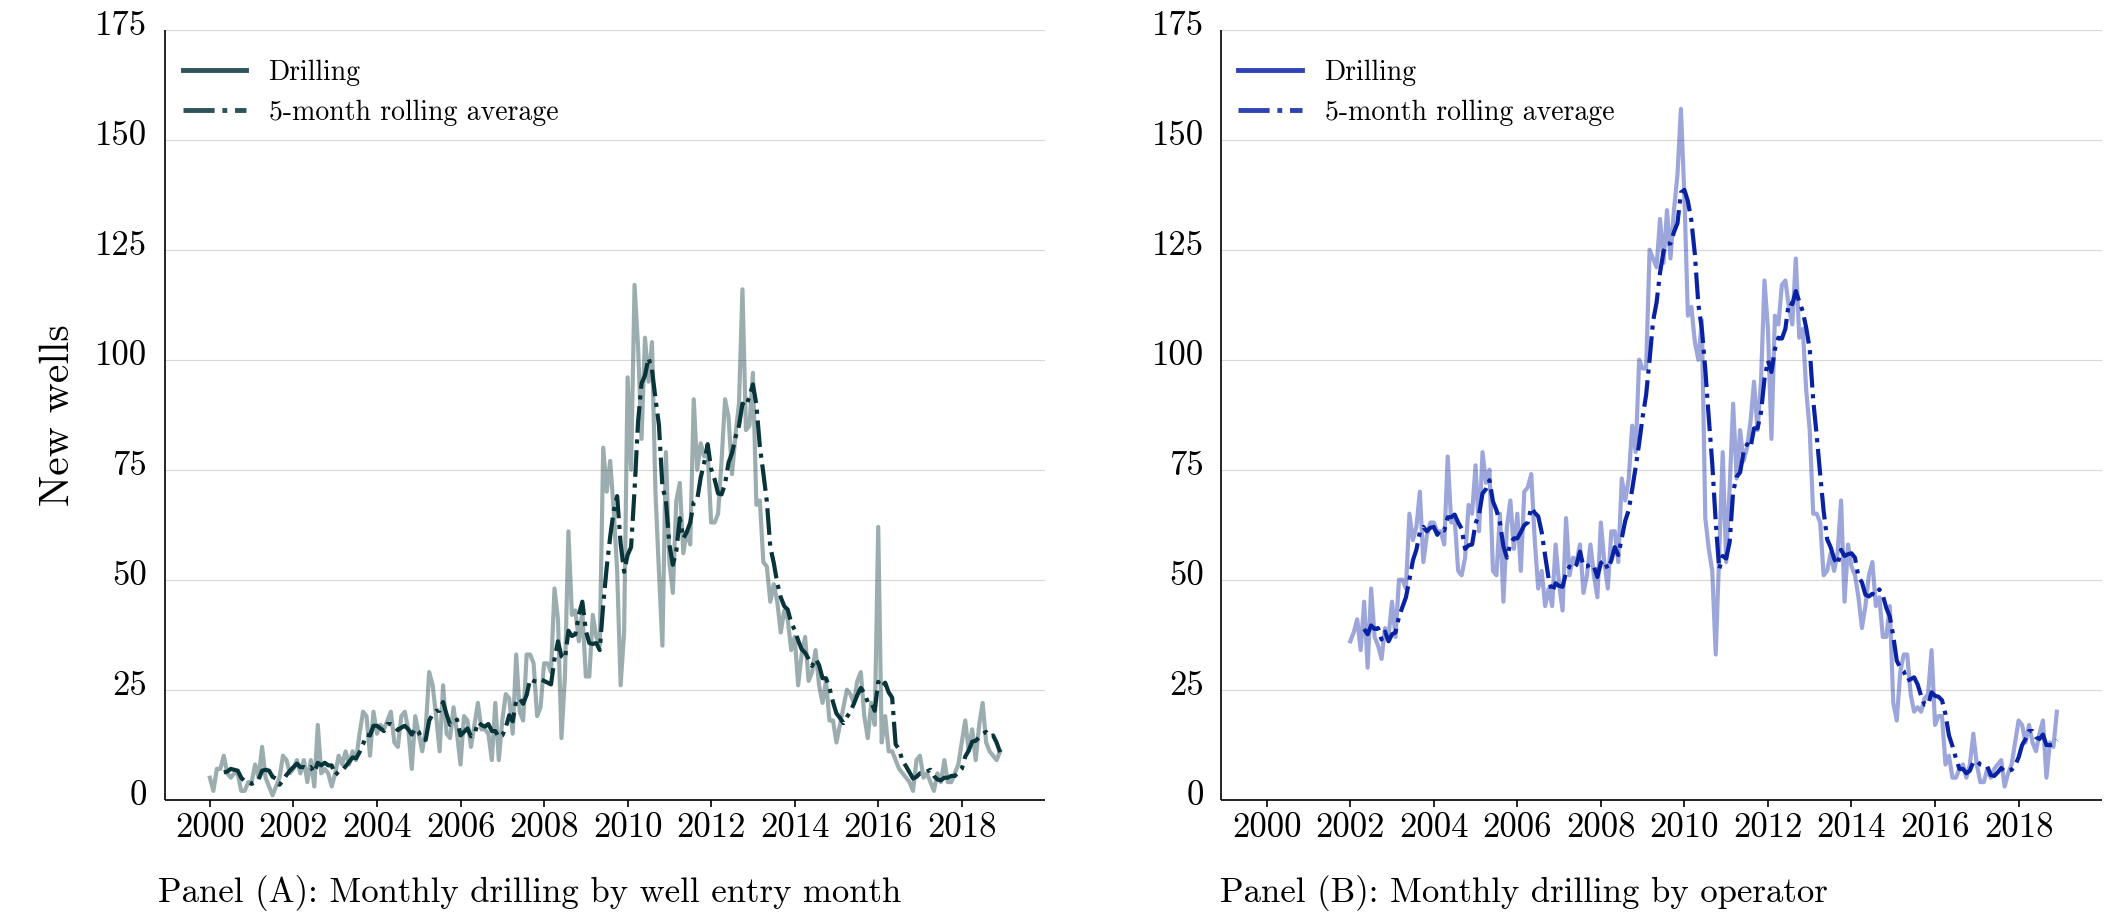

In [142]:
# Create subplots object
fig, axs = plt.subplots(figsize=(25,10), ncols=2, nrows=1)

# Apply format for both charts
for i in [0, 1]:

    # Y-axis settings
    axs[i].set_ylim(0, 175)
    axs[i].yaxis.set_label_coords(-0.1, 0.5)
    axs[i].yaxis.set_tick_params(labelleft=False, length=0)
    axs[i].yaxis.set_ticks(list(range(0, 176, 25)))

    # Y-axis labels
    for j in range(0,176,25):
    
            axs[i].text(
                -18, j-1, f'{j:,}', 
                ha="right", va="baseline", fontsize=25,
                fontfamily="cmr10", fontweight=100
            )

    # X-axis settings
    axs[i].set_xlim(-13, 240)
    axs[i].xaxis.set_ticks(list(range(0, 240, 24)))
    axs[i].xaxis.set_ticklabels(x_labels_02, fontsize=25, fontweight=100, fontfamily="cmr10")
    axs[i].xaxis.set_tick_params(length=5, width=1.2)

    # Spine settings
    axs[i].spines["bottom"].set_lw(1.2)
    axs[i].spines["bottom"].set_capstyle("butt")
    axs[i].spines['left'].set_lw(1.2)
    axs[i].spines['left'].set_capstyle("butt")
    axs[i].spines["top"].set_visible(False)
    axs[i].spines["right"].set_visible(False)

    # Grid
    axs[i].grid(axis='y', alpha=0.5)

# X-axis title
axs[0].set_ylabel('New wells', fontsize=30, fontweight=100, fontfamily="cmr10") # <- Axis name label

# Plot series

# Monthly drilling by entry month
axs[0].plot(df_drill['n_wells_pr'], lw=3, color="#08343A", alpha=0.4)
axs[0].plot(df_drill['n_wells_pr'].rolling(5).mean(), color="#08343A", lw=3, linestyle='dashdot')

# Monthy drilling by operator
axs[1].plot(df_drill['n_wells_op'], lw=3, color="#0922A4", alpha=0.4)
axs[1].plot(df_drill['n_wells_op'].rolling(5).mean(), color="#0922A4", lw=3, linestyle='dashdot')

# Legend settings
legend_handles_pr = [
    lines.Line2D([0], [0], color="#08343A", lw=3.5, alpha=0.85, label="Drilling"),
    lines.Line2D([0], [0], color="#08343A", lw=3.5, ls='dashdot', alpha=0.85, label="5-month rolling average")
]

legend_handles_op = [
    lines.Line2D([0], [0], color="#0922A4", lw=3.5, alpha=0.85, label="Drilling"),
    lines.Line2D([0], [0], color="#0922A4", lw=3.5, ls='dashdot', alpha=0.85, label="5-month rolling average")
]

# Display legend
axs[0].legend(
    handles=legend_handles_pr,
    loc="lower left",
    bbox_to_anchor=(-0.08, 0.85),
    bbox_transform=ax.transAxes,
    frameon=False,
    ncol=1,
    handlelength=2.3,
    columnspacing=1.0,
    prop={"family": "cmr10", "size": 20}
)

axs[1].legend(
    handles=legend_handles_op,
    loc="lower left",
    bbox_to_anchor=(0.465, 0.85),
    bbox_transform=ax.transAxes,
    frameon=False,
    ncol=1,
    handlelength=2.3,
    columnspacing=1.0,
    prop={"family": "cmr10", "size": 20}
)

# Chart titles
axs[0].text(
    0.112, -0.09, 
    r"Panel (A): Monthly drilling by well entry month",
    transform=ax.transAxes,
    ha="center",
    va="top",
    fontsize=25,
    fontfamily="cmr10",
    fontweight=1000
)

axs[1].text(
    0.625, -0.09, 
    'Panel (B): Monthly drilling by operator',
    transform=ax.transAxes,
    ha="center",
    va="top",
    fontsize=25,
    fontfamily="cmr10",
    fontweight=1000
)

# Tight layout
#fig.tight_layout()

# Show plot
plt.show()
